Processing subject 1/68 ...
Processing subject 2/68 ...
Processing subject 3/68 ...
Processing subject 4/68 ...
Processing subject 5/68 ...
Processing subject 6/68 ...
Processing subject 7/68 ...
Processing subject 8/68 ...
Processing subject 9/68 ...
Processing subject 10/68 ...
Processing subject 11/68 ...
Processing subject 12/68 ...
Processing subject 13/68 ...
Processing subject 14/68 ...
Processing subject 15/68 ...
Processing subject 16/68 ...
Processing subject 17/68 ...
Processing subject 18/68 ...
Processing subject 19/68 ...
Processing subject 20/68 ...
Processing subject 21/68 ...
Processing subject 22/68 ...
Processing subject 23/68 ...
Processing subject 24/68 ...
Processing subject 25/68 ...
Processing subject 26/68 ...
Processing subject 27/68 ...
Processing subject 28/68 ...
Processing subject 29/68 ...
Processing subject 30/68 ...
Processing subject 31/68 ...
Processing subject 32/68 ...
Processing subject 33/68 ...
Processing subject 34/68 ...
Processing subject 35/6

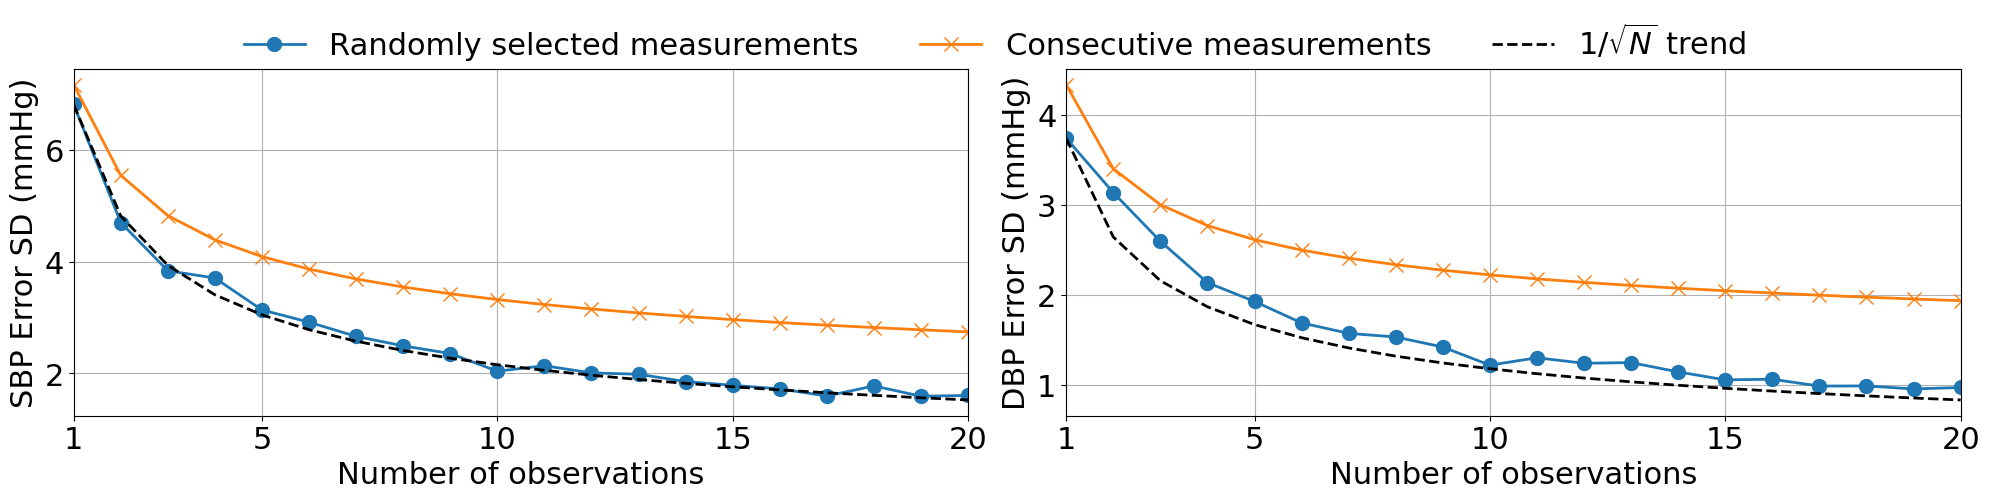

effect_of_number_of_observations.png was saved successfully!


In [1]:
import matplotlib.pyplot as plt
from utils import *

N_max = 20                                  # maximum number of observations
M = 10                                      # number of Monte Carlo simulations
RANDOM_SEED = 42                            # random seed for reproducibility
rng = np.random.default_rng(RANDOM_SEED)

fig_dir = '../figures'
os.makedirs(fig_dir, exist_ok=True)
BP_dir = '../results/simulated_BP/2p0'
files = sorted(os.listdir(BP_dir))
files = [file for file in files if file.endswith('.npz') and file != 'mean_cov.npz']
subjects = [file.split('.')[0] for file in files]
nSubject = len(subjects)
#%% All the subjects analysis

errors_ml_all = np.zeros((M, 2, N_max+1, nSubject))
errors_ml_seq_all = {}

for k, file in enumerate(files):
    print(f'Processing subject {k+1}/{nSubject} ...')
    path = f'{BP_dir}/{file}'
    data = np.load(path)
    BP_tru = data['BP'][:2, :]
    BP_est = data['BP'][2:, :]
    err = BP_est - BP_tru
    C_w = np.cov(err)
    mu_w = np.mean(err, axis=1)

    for N in np.arange(1, N_max + 1):
        errors_ml = []
        for i in range(M):
            N_samples = BP_est.shape[1]
            indices = rng.choice(N_samples, size=N, replace=False)
            x = BP_est[:, indices]
            x_true = BP_tru[:, indices]
            bp_corrected_ml = bias_correction_ML(x, mu_w).flatten()
            errors_ml.append(np.mean(x_true, axis=1) - bp_corrected_ml)
        errors_ml_all[:, :, N, k] = np.array(errors_ml)

    errors_ml_seq_all[k] = []
    for N in np.arange(1, N_max + 1):
        errors_ml = []
        for i in range(N, N_samples):
            x = BP_est[:, i - N:i]
            x_true = BP_tru[:, i - N:i]
            bp_corrected_ml = bias_correction_ML(x, mu_w).flatten()
            errors_ml.append(np.mean(x_true, axis=1) - bp_corrected_ml)
        errors_ml_seq_all[k].append(np.array(errors_ml))


std_bayes_all = np.zeros((N_max, 2))
for N in np.arange(1, N_max + 1):
    std_bayes_all[N-1, 0] = np.std(errors_ml_all[:, 0, N, :].reshape(-1, 1))
    std_bayes_all[N-1, 1] = np.std(errors_ml_all[:, 1, N, :].reshape(-1, 1))


std_bayes_seq_all = np.zeros((N_max, 2))
for N in np.arange(1, N_max + 1):
    values = []
    for k in range(nSubject):
        values.append(errors_ml_seq_all[k][N-1])
    std_bayes_seq_all[N-1, 0] = np.std(np.concatenate(values)[:, 0])
    std_bayes_seq_all[N-1, 1] = np.std(np.concatenate(values)[:, 1])

#%%
# Plot formatting options
FIG_SIZE = (20, 5)
XLABEL_FONT_SIZE = 22
YLABEL_FONT_SIZE = 22
XTICK_FONT_SIZE = 22
YTICK_FONT_SIZE = 22
LEGEND_FONT_SIZE = 22
LINE_WIDTH = 2
MARKER_SIZE = 10

RANDOM_COLOR = 'C0'
CONSECUTIVE_COLOR = 'C1'
TREND_COLOR = 'black'

fig, axes = plt.subplots(1, 2, figsize=FIG_SIZE)
x = np.arange(1, N_max + 1)

# SBP
trend_sbp = std_bayes_all[0, 0] / np.sqrt(x)
axes[0].plot(x, std_bayes_all[:, 0], marker='o', label='Randomly selected measurements', color=RANDOM_COLOR, markersize=MARKER_SIZE, linewidth=LINE_WIDTH)
axes[0].plot(x, std_bayes_seq_all[:, 0], marker='x', label='Consecutive measurements', color=CONSECUTIVE_COLOR, markersize=MARKER_SIZE, linewidth=LINE_WIDTH)
axes[0].plot(x, trend_sbp, linestyle='--', label=r'$1/\sqrt{N}$ trend', color=TREND_COLOR, linewidth=LINE_WIDTH)
axes[0].set_xticks([1, 5, 10, 15, 20])
# axes[0].set_ylim(0, 8)
axes[0].set_ylabel('SBP Error SD (mmHg)', fontsize=YLABEL_FONT_SIZE)
axes[0].set_xlabel('Number of observations', fontsize=XLABEL_FONT_SIZE)
axes[0].set_xlim(1, N_max)
axes[0].tick_params(axis='x', labelsize=XTICK_FONT_SIZE)
axes[0].tick_params(axis='y', labelsize=YTICK_FONT_SIZE)
axes[0].grid()

# DBP
trend_dbp = std_bayes_all[0, 1] / np.sqrt(x)
axes[1].plot(x, std_bayes_all[:, 1], marker='o', label='Randomly selected measurements', color=RANDOM_COLOR, markersize=MARKER_SIZE, linewidth=LINE_WIDTH)
axes[1].plot(x, std_bayes_seq_all[:, 1], marker='x', label='Consecutive measurements', color=CONSECUTIVE_COLOR, markersize=MARKER_SIZE, linewidth=LINE_WIDTH)
axes[1].plot(x, trend_dbp, linestyle='--', label=r'$1/\sqrt{N}$ trend', color=TREND_COLOR, linewidth=LINE_WIDTH)
axes[1].set_xticks([1, 5, 10, 15, 20])
axes[1].set_xlim(1, N_max)
# axes[1].set_ylim(0, 8)
axes[1].set_ylabel('DBP Error SD (mmHg)', fontsize=YLABEL_FONT_SIZE)
axes[1].set_xlabel('Number of observations', fontsize=XLABEL_FONT_SIZE)
axes[1].tick_params(axis='x', labelsize=XTICK_FONT_SIZE)
axes[1].tick_params(axis='y', labelsize=YTICK_FONT_SIZE)
axes[1].grid()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=LEGEND_FONT_SIZE, frameon=False)
fig.tight_layout(rect=[0, 0.0, 1, 0.9])

path = f'{fig_dir}/effect_of_number_of_observations.png'
plt.savefig(path, dpi=300)
plt.show()
plt.close(fig)

print('effect_of_number_of_observations.png was saved successfully!')